# T1: Red Compartida


In [ ]:
import torch, torch.nn as nn, numpy as np, gymnasium as gym
import matplotlib.pyplot as plt
from torch.distributions import Categorical


class ActorCriticNet(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=256):
        super().__init__()
        self.tronco = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
        )
        self.cabeza_actor = nn.Linear(hidden, n_actions)
        self.cabeza_critico = nn.Linear(hidden, 1)

    def forward(self, x):
        feat = self.tronco(x)
        dist = Categorical(logits=self.cabeza_actor(feat))
        value = self.cabeza_critico(feat).squeeze(-1)
        return dist, value


# ── Setup y verificacion ──────────────────────────────────────
env = gym.make("CartPole-v1")
model = ActorCriticNet(4, 2, hidden=256)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

s = torch.FloatTensor(env.reset()[0]).unsqueeze(0)  # (1, 4)
dist, val = model(s)
print(f"Acciones: {dist.probs.detach().numpy().round(3)}")
print(f"Valor V(s): {val.item():.4f}")
print(f"Entropia H(pi): {dist.entropy().item():.4f}")
print(f"Entropia maxima (uniforme): {torch.log(torch.tensor(2.0)):.4f}")

Acciones: [[0.477 0.523]]
Valor V(s): -0.0935
Entropia H(pi): 0.6921
Entropia maxima (uniforme): 0.6931


# T2: Loop A2C


In [13]:
def train_a2c_episode(
    env, model, optimizer, gamma=0.99, c_v=0.5, c_e=0.01, max_grad_norm=0.5
):
    """Un episodio completo de A2C. Retorna metricas."""
    log_probs, values, rewards, entropies = [], [], [], []
    obs, _ = env.reset()
    done = False

    while not done:
        s = torch.FloatTensor(obs)
        dist, val = model(s)
        action = dist.sample()
        obs, r, term, trunc, _ = env.step(action.item())
        done = term or trunc
        log_probs.append(dist.log_prob(action))
        values.append(val)
        rewards.append(r)
        entropies.append(dist.entropy())

    G, returns = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G
        returns.insert(0, G)
    returns = torch.tensor(returns, dtype=torch.float32)
    returns = (returns - returns.mean()) / (returns.std() + 1e-8)

    log_probs = torch.stack(log_probs)
    values = torch.stack(values)
    entropies = torch.stack(entropies)
    advantages = returns - values.detach()

    L_actor = -(log_probs * advantages).mean()
    L_critic = c_v * (returns - values).pow(2).mean()
    L_entropy = -c_e * entropies.mean()
    L_total = L_actor + L_critic + L_entropy

    optimizer.zero_grad()
    L_total.backward()
    if max_grad_norm is not None:
        nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
    optimizer.step()

    return (sum(rewards), L_actor.item(), L_critic.item(), entropies.mean().item())


# T3: Entrenar y Graficar


In [ ]:
# Entrenar A2C por 1000 episodios
N_EP = 1000
hist = {"reward": [], "L_actor": [], "L_critic": [], "entropy": []}

for ep in range(N_EP):
    r, la, lc, h = train_a2c_episode(env, model, optimizer)
    hist["reward"].append(r)
    hist["L_actor"].append(la)
    hist["L_critic"].append(lc)
    hist["entropy"].append(h)
    if ep % 100 == 0:
        print(
            f"Ep {ep:>4d} | R={np.mean(hist['reward'][-20:]):>7.1f} | "
            f"H={np.mean(hist['entropy'][-20:]):.4f} | "
            f"L_a={np.mean(hist['L_actor'][-20:]):.4f}"
        )

Ep    0 | R=   12.0 | H=0.6918 | L_a=0.0763
Ep  100 | R=  123.0 | H=0.5901 | L_a=-0.7016
Ep  200 | R=  222.2 | H=0.5729 | L_a=-0.0034
Ep  300 | R=  171.7 | H=0.5603 | L_a=0.0476
Ep  400 | R=  207.4 | H=0.4816 | L_a=0.0323
Ep  500 | R=  224.2 | H=0.5347 | L_a=-0.0361
Ep  600 | R=  349.5 | H=0.5397 | L_a=-0.0239
Ep  700 | R=  273.2 | H=0.5394 | L_a=-0.0036
Ep  800 | R=  218.5 | H=0.5315 | L_a=0.0183
Ep  900 | R=  381.8 | H=0.5279 | L_a=0.1186


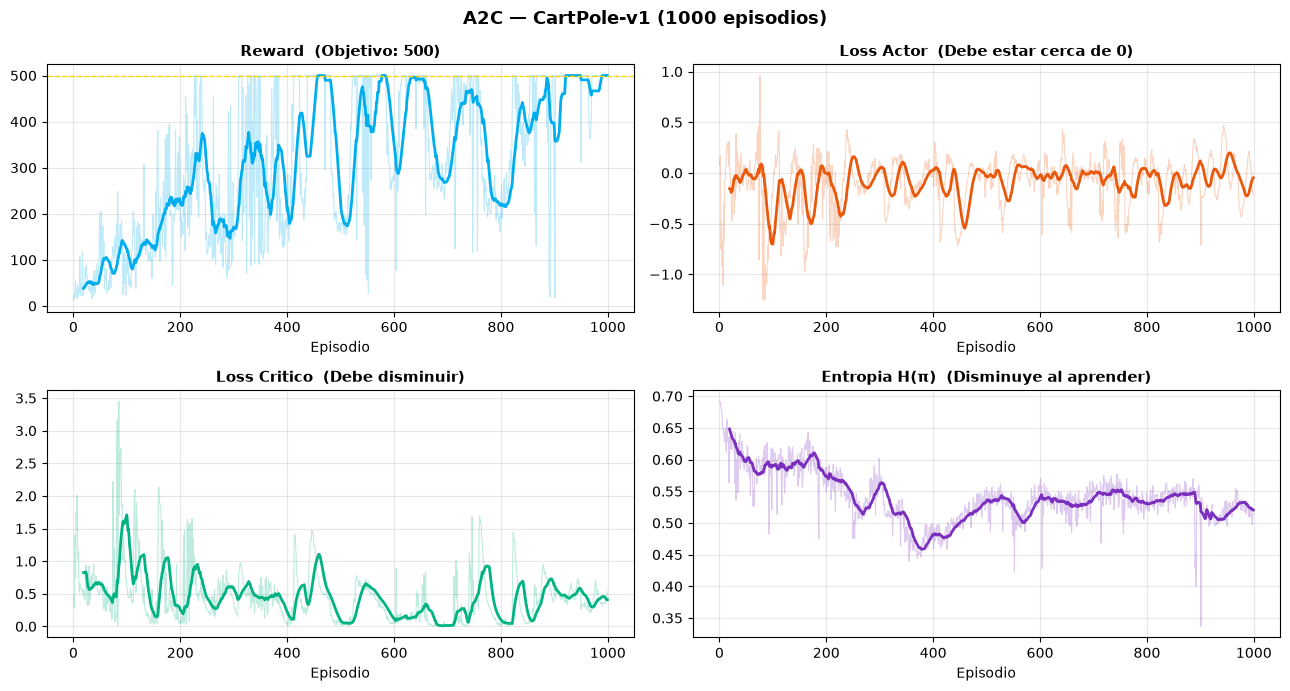

In [ ]:
def plot_a2c_metrics(hist, window=20, title="A2C — CartPole-v1"):
    fig, axes = plt.subplots(2, 2, figsize=(13, 7))
    metrics = [
        ("reward", "Reward", "#00AEEF", f"Objetivo: 500"),
        ("L_actor", "Loss Actor", "#EA580C", "Debe estar cerca de 0"),
        ("L_critic", "Loss Critico", "#00B383", "Debe disminuir"),
        ("entropy", "Entropia H(π)", "#7B2FBE", "Disminuye al aprender"),
    ]
    for ax, (key, label, color, nota) in zip(axes.flat, metrics):
        vals = np.array(hist[key])
        ma = np.convolve(vals, np.ones(window) / window, mode="valid")
        ax.plot(vals, alpha=0.25, color=color, linewidth=0.8)
        ax.plot(range(window - 1, len(vals)), ma, color=color, linewidth=2)
        ax.set_title(f"{label}  ({nota})", fontsize=11, fontweight="bold")
        ax.set_xlabel("Episodio")
        ax.grid(alpha=0.3)
        if key == "reward":
            ax.axhline(500, color="gold", linestyle="--", lw=1)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_a2c_metrics(hist, window=20, title="A2C — CartPole-v1 (1000 episodios)")

In [10]:
# REINFORCE sin baseline: guardar recompensa y entropia media por episodio.
def reinforce_simple(env, n_ep=1000, gamma=0.99, lr=1e-3):
    from torch.optim import Adam

    pol = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 2))
    opt = Adam(pol.parameters(), lr=lr)
    hist_r, hist_h = [], []

    for _ in range(n_ep):
        log_ps, rews, entropies = [], [], []
        obs, _ = env.reset()
        while True:
            d = Categorical(logits=pol(torch.FloatTensor(obs)))
            a = d.sample()
            obs, r, te, tr, _ = env.step(a.item())
            log_ps.append(d.log_prob(a))
            rews.append(r)
            entropies.append(d.entropy().item())
            if te or tr:
                break

        G, rets = 0, []
        for r in reversed(rews):
            G = r + gamma * G
            rets.insert(0, G)
        rets = torch.tensor(rets, dtype=torch.float32)
        rets = (rets - rets.mean()) / (rets.std() + 1e-8)
        loss = -(torch.stack(log_ps) * rets).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()

        hist_r.append(sum(rews))
        hist_h.append(float(np.mean(entropies)))

    return hist_r, hist_h


rewards_reinforce, entropies_reinforce = reinforce_simple(env, n_ep=1000)

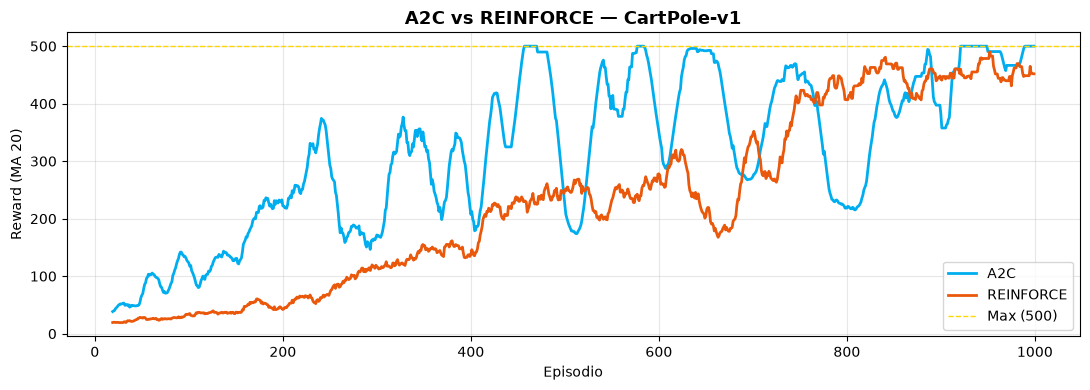

In [ ]:
# Graficar ambos en una figura
fig, ax = plt.subplots(figsize=(11, 4))
window = 20
for rewards, label, color in [
    (hist["reward"], "A2C", "#00AEEF"),
    (rewards_reinforce, "REINFORCE", "#EA580C"),
]:
    ma = np.convolve(rewards, np.ones(window) / window, mode="valid")
    ax.plot(range(window - 1, len(rewards)), ma, color=color, lw=2, label=label)
ax.axhline(500, color="gold", linestyle="--", lw=1, label="Max (500)")
ax.set_title("A2C vs REINFORCE — CartPole-v1", fontweight="bold", fontsize=13)
ax.set_xlabel("Episodio")
ax.set_ylabel("Reward (MA 20)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# T4: Entropia


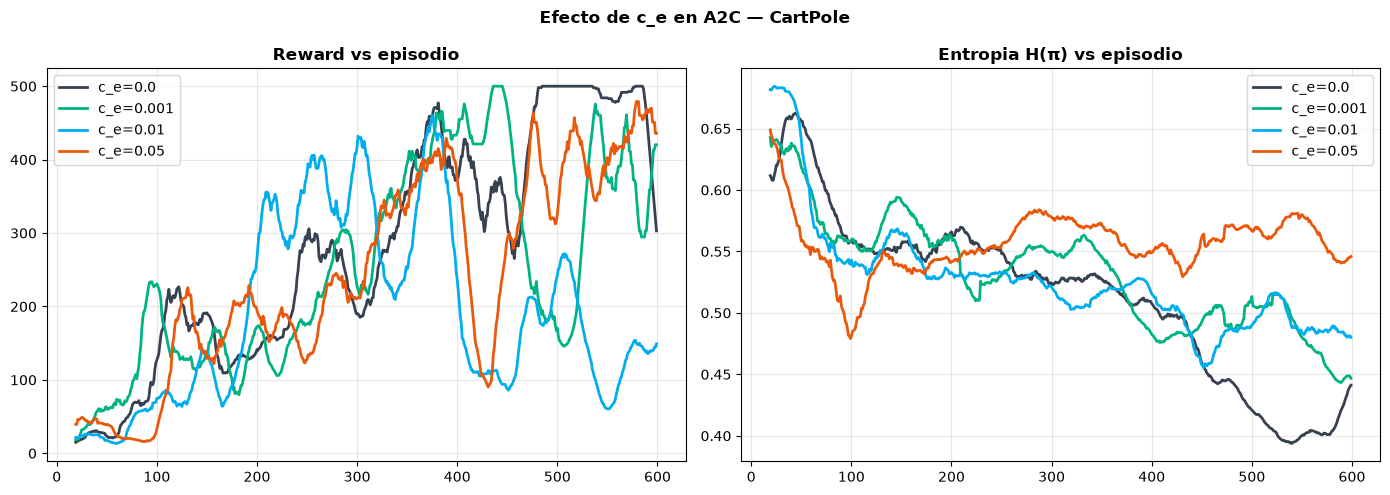

In [7]:
# Variar c_e y comparar
ce_values = [0.0, 0.001, 0.01, 0.05]
results_ce = {}

for c_e in ce_values:
    model_ce = ActorCriticNet(4, 2, hidden=256)
    opt_ce = torch.optim.Adam(model_ce.parameters(), lr=1e-3)
    rewards_ce, entropies_ce = [], []

    for ep in range(600):
        r, _, _, h = train_a2c_episode(env, model_ce, opt_ce, c_e=c_e)
        rewards_ce.append(r)
        entropies_ce.append(h)

    results_ce[c_e] = {"rewards": rewards_ce, "entropies": entropies_ce}

# Graficar reward vs episodio para cada c_e
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = {0.0: "#374151", 0.001: "#00B383", 0.01: "#00AEEF", 0.05: "#EA580C"}
for c_e, data in results_ce.items():
    ma_r = np.convolve(data["rewards"], np.ones(20) / 20, mode="valid")
    ma_h = np.convolve(data["entropies"], np.ones(20) / 20, mode="valid")
    ax1.plot(range(19, 600), ma_r, color=colors[c_e], lw=2, label=f"c_e={c_e}")
    ax2.plot(range(19, 600), ma_h, color=colors[c_e], lw=2, label=f"c_e={c_e}")
ax1.set_title("Reward vs episodio", fontweight="bold")
ax1.legend()
ax1.grid(alpha=0.3)
ax2.set_title("Entropia H(π) vs episodio", fontweight="bold")
ax2.legend()
ax2.grid(alpha=0.3)
plt.suptitle("Efecto de c_e en A2C — CartPole", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Preguntas


## Q1. Compara las curvas de entropia $H(π)$ de A2C vs REINFORCE a lo largo del entrenamiento. ¿Cual mantiene mayor exploracion por más tiempo? ¿Por que tiene sentido dado el tipo de actualizacion?

> Hint: REINFORCE usa retornos Monte Carlo sin baseline. A2C pondera la politica con la ventaja del critico y suma el bono de entropia. En esta implementacion, ambos actualizan al terminar cada episodio.

**Respuesta.** En la mayor parte del entrenamiento, REINFORCE mantiene una entropía mayor: tras una caída inicial, su curva se recupera y queda por encima de A2C durante buena parte del resto. En los últimos 100 episodios, la entropía media es **0.550** para REINFORCE y **0.517** para A2C; en los primeros 100, A2C había empezado algo más alto (**0.604** frente a **0.583**).

REINFORCE usa retornos Monte Carlo sin una línea base del crítico, por lo que sus actualizaciones tienen mayor varianza y la curva fluctúa más. A2C usa la ventaja estimada por el crítico para reducir esa varianza y añade el bono de entropía c_e=0.01, aunque ese bono no garantiza que su entropía observada supere la de REINFORCE. Además, en esta implementación ambos métodos actualizan al terminar cada episodio; la comparación no es entre actualización online y por episodio.


A2C: H media episodios 1-100 = 0.604; episodios finales = 0.517
REINFORCE: H media episodios 1-100 = 0.583; episodios finales = 0.550


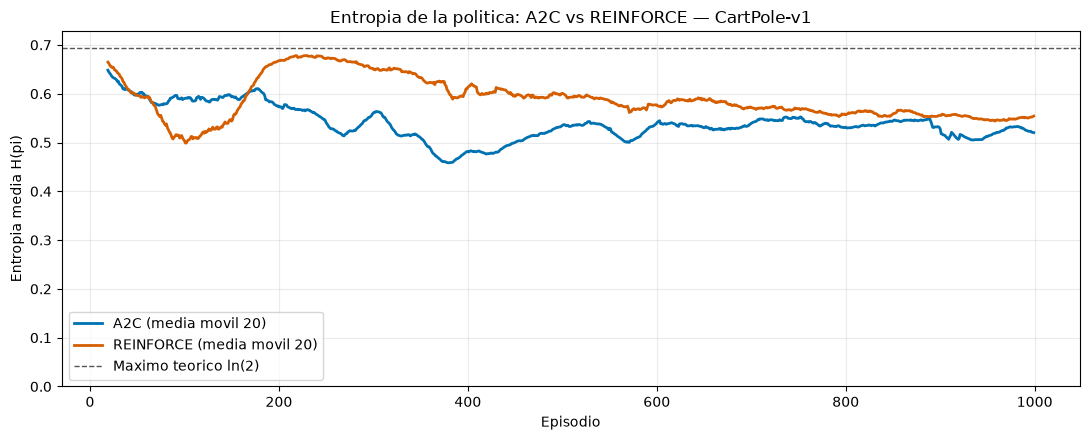

Lectura: A2C usa la ventaja estimada por el critico y c_e=0.01 incentiva la entropia. En este notebook ambos metodos actualizan al terminar cada episodio; la diferencia no proviene de una actualizacion online paso a paso.


In [11]:
# Curvas comparables: entropia media por episodio, suavizada en ventanas de 20.
window = 20
fig, ax = plt.subplots(figsize=(11, 4.5))
for values, label, color in [
    (hist["entropy"], "A2C", "#0072B2"),
    (entropies_reinforce, "REINFORCE", "#D55E00"),
]:
    values = np.asarray(values, dtype=float)
    moving = np.convolve(values, np.ones(window) / window, mode="valid")
    episodes = np.arange(window - 1, len(values))
    ax.plot(
        episodes, moving, color=color, linewidth=2, label=f"{label} (media movil 20)"
    )
    print(
        f"{label}: H media episodios 1-100 = {values[:100].mean():.3f}; "
        f"episodios finales = {values[-100:].mean():.3f}"
    )

ax.axhline(
    np.log(2),
    color="#555555",
    linestyle="--",
    linewidth=1,
    label="Maximo teorico ln(2)",
)
ax.set(
    title="Entropia de la politica: A2C vs REINFORCE — CartPole-v1",
    xlabel="Episodio",
    ylabel="Entropia media H(pi)",
)
ax.set_ylim(0, np.log(2) * 1.05)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(
    "Lectura: A2C usa la ventaja estimada por el critico y c_e=0.01 incentiva "
    "la entropia. En este notebook ambos metodos actualizan al terminar cada "
    "episodio; la diferencia no proviene de una actualizacion online paso a paso."
)

## Q2. Con $c_e=0$ (sin término de entropia), ¿A2C converge igual de bien que con $c_e=0.01$? ¿En que tipo de entornos esperarias que la diferencia sea mayor?

> Hint: En CartPole, con recompensa por paso, la diferencia puede ser pequena. Se espera un efecto mayor en tareas con recompensas escasas o muy retrasadas, donde explorar es clave.

**Respuesta.** En esta corrida, no: el promedio de recompensa de los últimos 20 episodios fue **302.9** con c_e=0 y **148.9** con c_e=0.01. Sin embargo, c_e=0 llegó brevemente a 500 y luego cayó; no mantuvo ese rendimiento. Su entropía final también fue menor (**0.441** frente a **0.480**), señal de una política más concentrada. c_e=0.01 conservó algo más de exploración, pero aquí eso no produjo una recompensa final mayor.

La diferencia se espera más marcada en tareas con recompensas escasas o retrasadas, donde explorar puede ser necesario para encontrar las pocas trayectorias que dan recompensa. Como esta comparación usa una sola corrida por configuración y ambas curvas fluctúan, no basta para concluir que c_e=0 sea mejor en general.


c_e=0.0: reward medio ultimos 20 episodios = 302.9; entropia media final = 0.441
c_e=0.01: reward medio ultimos 20 episodios = 148.9; entropia media final = 0.480


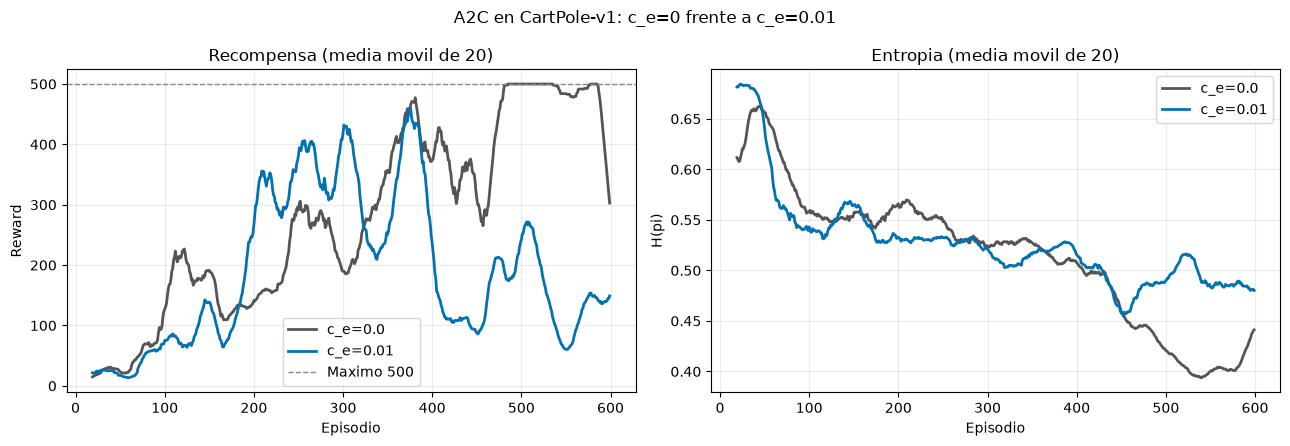

CartPole ofrece recompensa en cada paso, por lo que la diferencia puede ser pequena. Se espera un efecto mayor en entornos con recompensas escasas, donde mantener la exploracion ayuda a descubrir las trayectorias que las producen.


In [ ]:
# Comparar la recompensa y la entropia de las dos configuraciones preguntadas.
window = 20
ce_values = (0.0, 0.01)
colors = {0.0: "#555555", 0.01: "#0072B2"}
fig, (ax_reward, ax_entropy) = plt.subplots(1, 2, figsize=(13, 4.5))

for c_e in ce_values:
    data = results_ce[c_e]
    rewards = np.asarray(data["rewards"], dtype=float)
    entropies = np.asarray(data["entropies"], dtype=float)
    reward_ma = np.convolve(rewards, np.ones(window) / window, mode="valid")
    entropy_ma = np.convolve(entropies, np.ones(window) / window, mode="valid")
    episodes = np.arange(window - 1, len(rewards))
    ax_reward.plot(
        episodes, reward_ma, color=colors[c_e], linewidth=2, label=f"c_e={c_e}"
    )
    ax_entropy.plot(
        episodes, entropy_ma, color=colors[c_e], linewidth=2, label=f"c_e={c_e}"
    )

    print(
        f"c_e={c_e}: reward medio ultimos 20 episodios = {rewards[-20:].mean():.1f}; "
        f"entropia media final = {entropies[-20:].mean():.3f}"
    )

ax_reward.axhline(500, color="#888888", linestyle="--", linewidth=1, label="Maximo 500")
ax_reward.set(
    title="Recompensa (media movil de 20)", xlabel="Episodio", ylabel="Reward"
)
ax_entropy.set(title="Entropia (media movil de 20)", xlabel="Episodio", ylabel="H(pi)")
for ax in (ax_reward, ax_entropy):
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("A2C en CartPole-v1: c_e=0 frente a c_e=0.01")
plt.tight_layout()
plt.show()

print(
    "CartPole ofrece recompensa en cada paso, por lo que la diferencia puede ser "
    "pequena. Se espera un efecto mayor en entornos con recompensas escasas, donde "
    "mantener la exploracion ayuda a descubrir las trayectorias que las producen."
)

## Q3. Gradient clipping con $max\_norm=0.5$: ¿que pasaria si lo quitas ($max\_norm=infinito$)? Diseña un experimento para verificarlo y ejecutalo.

> Hint: Sin clipping: actualizaciones grandes pueden colapsar la politica. Espera ver reward que sube rapidamente y luego cae en picado.


Con clipping (max_norm=0.5): reward medio de los ultimos 20 episodios por semilla = [204.  342.  214.6]
Sin clipping: reward medio de los ultimos 20 episodios por semilla = [128.3 296.8 370.4]


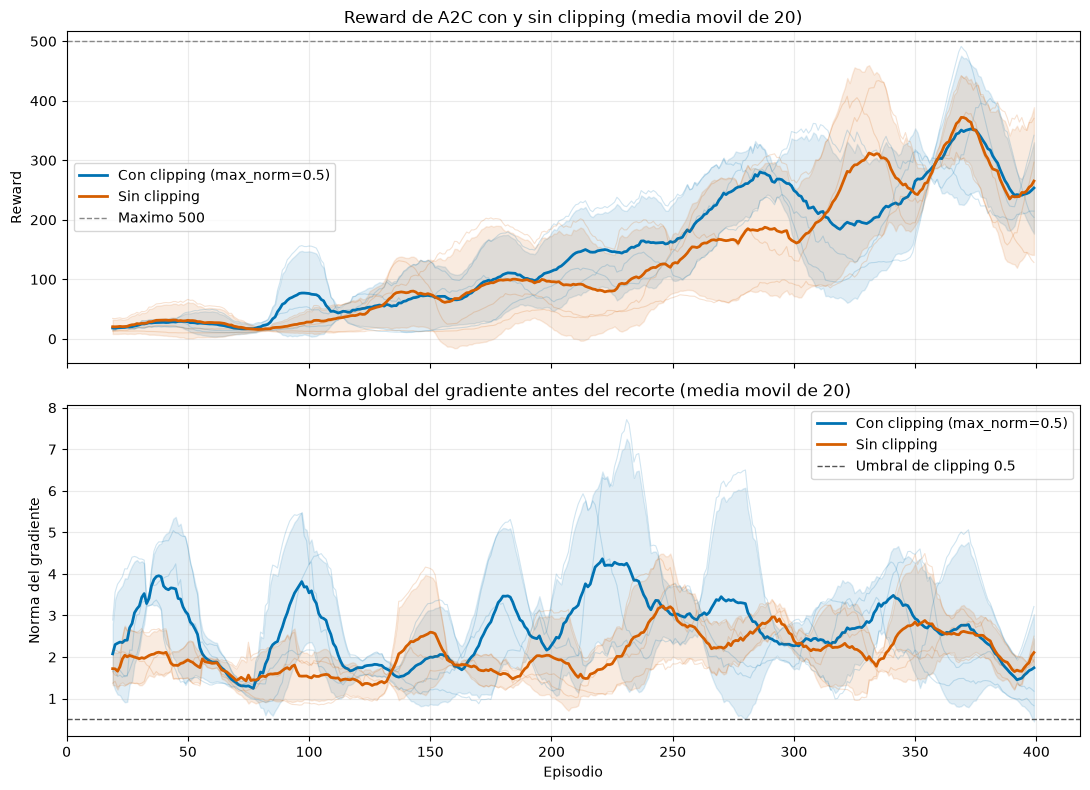

Busca una subida seguida de una caida sostenida del reward sin clipping; la curva de norma ayuda a relacionarla con gradientes grandes. La norma registrada es previa al recorte. CartPole es estocastico, por eso se comparan tres semillas pareadas.


In [14]:
# Entrenar sin clipping y mostrar las mismas cuatro metricas de plot_a2c_metrics.
# Se usan 1000 episodios para igualar la corrida A2C con clipping de la celda T3.
seed = 101
n_episodes = len(hist["reward"])
torch.manual_seed(seed)
env_no_clip = gym.make("CartPole-v1")
env_no_clip.reset(seed=seed)
model_no_clip = ActorCriticNet(4, 2, hidden=256)
optimizer_no_clip = torch.optim.Adam(model_no_clip.parameters(), lr=1e-3)

hist_no_clip = {"reward": [], "L_actor": [], "L_critic": [], "entropy": []}
for ep in range(n_episodes):
    reward, actor_loss, critic_loss, entropy = train_a2c_episode(
        env_no_clip,
        model_no_clip,
        optimizer_no_clip,
        max_grad_norm=None,
    )
    hist_no_clip["reward"].append(reward)
    hist_no_clip["L_actor"].append(actor_loss)
    hist_no_clip["L_critic"].append(critic_loss)
    hist_no_clip["entropy"].append(entropy)

    if ep % 100 == 0:
        print(
            f"Sin clipping | Ep {ep:>4d} | "
            f"R={np.mean(hist_no_clip['reward'][-20:]):>7.1f} | "
            f"H={np.mean(hist_no_clip['entropy'][-20:]):.4f} | "
            f"L_a={np.mean(hist_no_clip['L_actor'][-20:]):.4f}"
        )

plot_a2c_metrics(
    hist_no_clip,
    window=20,
    title=f"A2C sin clipping — CartPole-v1 ({n_episodes} episodios)",
)
env_no_clip.close()

print(
    "Compara este panel con el A2C de T3, entrenado con max_grad_norm=0.5. "
    "Una sola semilla sirve como inspeccion visual; la caida de reward no esta garantizada."
)
